# Project 01 – Week 2 Simulation

## Objective

Develop a SimPy-based discrete event simulation of a surface mining operation consisting of:

- 10 haul trucks
- 4 shovels
- 2 dumps
- 12-hour operating shift

The simulation models truck movement, queueing, loading, dumping, and stochastic breakdowns.

## Inputs

- Fleet size
- Service time distributions
- Breakdown distributions

## Outputs

- Cycle-level operational dataset
- Queue statistics
- Equipment utilization
- Production statistics
- 95% confidence intervals

## Foundation Paper

Moradi Afrapoli et al. (2019)

---

## System Description

Truck cycle:

Travel to Shovel
→ Queue
→ Load
→ Travel to Dump
→ Dump
→ Repeat

---

## Key Equations

Cycle Time

T_cycle = T_travel1 + T_queue + T_load + T_travel2 + T_dump

Utilization

U = Busy Time / Available Time

95% Confidence Interval

CI = mean ± 1.96 × (std / sqrt(n))

In [1]:
# WHAT:
# Import libraries and define model parameters

# INPUT:
# User-defined simulation assumptions

# OUTPUT:
# Global simulation configuration

import simpy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SHIFT_DURATION = 720

NUM_TRUCKS = 10
NUM_SHOVELS = 4
NUM_DUMPS = 2

MTBF = 120 * 60

TRAVEL_TO_SHOVEL = (5, 10)
LOAD_TIME = (3, 6)
TRAVEL_TO_DUMP = (6, 12)
DUMP_TIME = (1, 3)

REPAIR_TRI = (30, 90, 180)

random.seed(42)

# Simulation Components

### Dispatcher

Shortest queue dispatching policy.

Each truck selects the shovel with the smallest queue length.

### Breakdown Model

Failures follow an exponential distribution:

MTBF = 120 hr

Repair times follow a triangular distribution:

Triangular(30, 90, 180)

### Performance Metrics

- Cycle Time
- Queue Time
- Truck Utilization
- Shovel Utilization
- Production (completed cycles)

In [3]:
# WHAT:
# Define helper functions and data structures

# INPUT:
# Simulation parameters

# OUTPUT:
# Random generators, state objects and dispatcher

def travel_to_shovel():
    return random.uniform(*TRAVEL_TO_SHOVEL)

def loading_time():
    return random.uniform(*LOAD_TIME)

def travel_to_dump():
    return random.uniform(*TRAVEL_TO_DUMP)

def dump_time():
    return random.uniform(*DUMP_TIME)

def repair_time():
    return random.triangular(
        REPAIR_TRI[0],
        REPAIR_TRI[2],
        REPAIR_TRI[1]
    )


class TruckState:

    def __init__(self):

        self.broken = False


class TruckStats:

    def __init__(self, truck_id):

        self.id = truck_id

        self.busy_time = 0

        self.breakdowns = 0

        self.repair_time = 0

        self.cycles = 0


class ShovelStats:

    def __init__(self, shovel_id):

        self.id = shovel_id

        self.busy_time = 0


def choose_shovel(shovels):

    queue_lengths = [
        len(shovel.queue)
        for shovel in shovels
    ]

    return min(
        range(len(shovels)),
        key=lambda i: queue_lengths[i]
    )

In [4]:
# WHAT:
# Define mine operating processes

# INPUT:
# SimPy environment and resources

# OUTPUT:
# Truck movement and breakdown behaviour

def breakdown_process(
    env,
    state,
    truck_stats
):

    while True:

        time_to_failure = random.expovariate(
            1 / MTBF
        )

        yield env.timeout(time_to_failure)

        state.broken = True

        truck_stats.breakdowns += 1

        repair_duration = repair_time()

        truck_stats.repair_time += repair_duration

        yield env.timeout(repair_duration)

        state.broken = False


def truck_process(
    env,
    truck_id,
    state,
    truck_stats,
    shovels,
    shovel_stats,
    dumps,
    cycle_data
):

    while env.now < SHIFT_DURATION:

        cycle_start = env.now

        while state.broken:
            yield env.timeout(1)

        shovel_id = choose_shovel(shovels)

        shovel = shovels[shovel_id]

        travel1 = travel_to_shovel()

        truck_stats.busy_time += travel1

        yield env.timeout(travel1)

        queue_start = env.now

        with shovel.request() as req:

            yield req

            queue_time = env.now - queue_start

            load_duration = loading_time()

            shovel_stats[
                shovel_id
            ].busy_time += load_duration

            truck_stats.busy_time += (
                queue_time +
                load_duration
            )

            yield env.timeout(
                load_duration
            )

        travel2 = travel_to_dump()

        truck_stats.busy_time += travel2

        yield env.timeout(travel2)

        dump_id = random.randint(
            0,
            NUM_DUMPS - 1
        )

        with dumps[dump_id].request() as req:

            yield req

            dump_duration = dump_time()

            truck_stats.busy_time += dump_duration

            yield env.timeout(
                dump_duration
            )

        cycle_end = env.now

        truck_stats.cycles += 1

        cycle_data.append({

            "truck_id": truck_id,

            "shovel_id": shovel_id,

            "dump_id": dump_id,

            "queue_time_min": queue_time,

            "load_time_min": load_duration,

            "travel_to_shovel_min": travel1,

            "travel_to_dump_min": travel2,

            "dump_time_min": dump_duration,

            "cycle_time_min":
                cycle_end - cycle_start,

            "hour_of_shift":
                cycle_end / 60
        })

In [5]:
# WHAT:
# Execute one simulation replication

# INPUT:
# Mine configuration

# OUTPUT:
# Cycle-level dataset and replication KPIs

def run_replication(replication_id):

    env = simpy.Environment()

    cycle_data = []

    shovels = [
        simpy.Resource(
            env,
            capacity=1
        )
        for _ in range(NUM_SHOVELS)
    ]

    dumps = [
        simpy.Resource(
            env,
            capacity=1
        )
        for _ in range(NUM_DUMPS)
    ]

    truck_stats = []

    shovel_stats = [
        ShovelStats(i)
        for i in range(NUM_SHOVELS)
    ]

    for truck_id in range(NUM_TRUCKS):

        state = TruckState()

        stats = TruckStats(truck_id)

        truck_stats.append(stats)

        env.process(
            truck_process(
                env,
                truck_id,
                state,
                stats,
                shovels,
                shovel_stats,
                dumps,
                cycle_data
            )
        )

        env.process(
            breakdown_process(
                env,
                state,
                stats
            )
        )

    env.run(
        until=SHIFT_DURATION
    )

    cycle_df = pd.DataFrame(
        cycle_data
    )

    production = len(cycle_df)

    avg_cycle_time = cycle_df[
        "cycle_time_min"
    ].mean()

    avg_queue_time = cycle_df[
        "queue_time_min"
    ].mean()

    avg_truck_util = np.mean([
        truck.busy_time /
        SHIFT_DURATION
        for truck in truck_stats
    ])

    avg_shovel_util = np.mean([
        shovel.busy_time /
        SHIFT_DURATION
        for shovel in shovel_stats
    ])

    total_breakdowns = sum([
        truck.breakdowns
        for truck in truck_stats
    ])

    summary = {

        "replication":
            replication_id,

        "production":
            production,

        "avg_cycle_time":
            avg_cycle_time,

        "avg_queue_time":
            avg_queue_time,

        "avg_truck_util":
            avg_truck_util,

        "avg_shovel_util":
            avg_shovel_util,

        "total_breakdowns":
            total_breakdowns
    }

    return summary, cycle_df

In [6]:
# WHAT:
# Run all replications and aggregate outputs

# INPUT:
# Replication runner

# OUTPUT:
# Results dataframe, cycle dataframe and confidence interval

results = []

all_cycles = []

for rep in range(30):

    summary, cycle_df = run_replication(rep)

    results.append(summary)

    all_cycles.append(cycle_df)

results_df = pd.DataFrame(results)

cycle_df = pd.concat(
    all_cycles,
    ignore_index=True
)

# --------------------------------------------------
# 95% Confidence Interval for Production
# --------------------------------------------------

mean_production = results_df[
    "production"
].mean()

std_production = results_df[
    "production"
].std()

ci_margin = (
    1.96
    * std_production
    / np.sqrt(len(results_df))
)

ci_lower = mean_production - ci_margin

ci_upper = mean_production + ci_margin

print("\nProduction Statistics")

print(
    f"Mean Production: "
    f"{mean_production:.2f}"
)

print(
    f"95% CI: "
    f"[{ci_lower:.2f}, "
    f"{ci_upper:.2f}]"
)

# --------------------------------------------------
# Save Outputs
# --------------------------------------------------

cycle_df.to_csv(
    "cycle_data.csv",
    index=False
)

results_df.to_csv(
    "replication_summary.csv",
    index=False
)


Production Statistics
Mean Production: 251.70
95% CI: [250.10, 253.30]


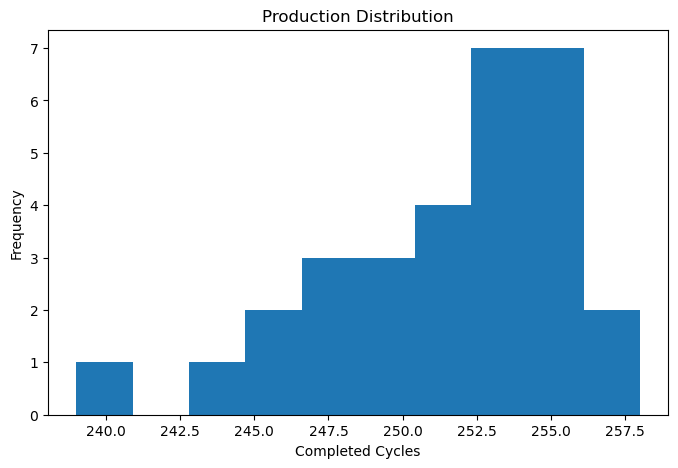

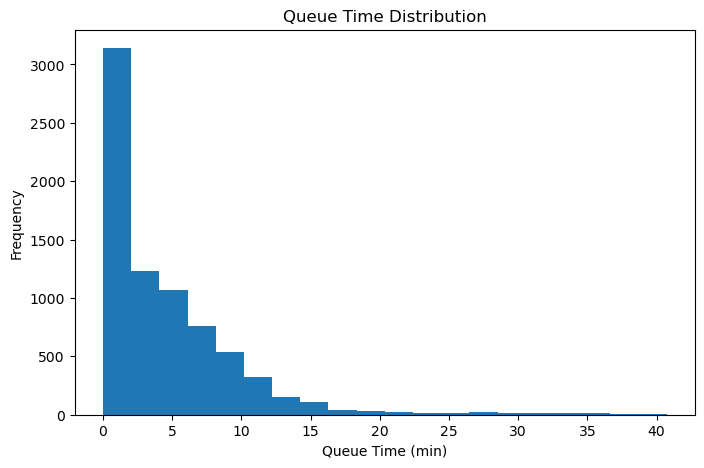


KPI SUMMARY



,KPI,Value,Interpretation
0,Average Production,251.700,Completed haul cycles per shift
1,Average Cycle Time,27.990,Typical truck cycle duration
2,Average Queue Time,4.380,Average congestion level
3,Average Truck Utilization,0.980,Fraction of truck busy time
4,Average Shovel Utilization,0.403,Fraction of shovel busy time
5,Average Breakdowns,1.070,Expected failures per shift


In [7]:
# WHAT:
# Visualize simulation outputs and summarize KPIs

# INPUT:
# Results dataframe and cycle dataframe

# OUTPUT:
# Plots and KPI summary table

# --------------------------------------------------
# Production Histogram
# --------------------------------------------------

plt.figure(figsize=(8,5))

plt.hist(
    results_df["production"],
    bins=10
)

plt.title(
    "Production Distribution"
)

plt.xlabel(
    "Completed Cycles"
)

plt.ylabel(
    "Frequency"
)

plt.savefig(
    "production_histogram.png"
)

plt.show()

# --------------------------------------------------
# Queue Time Histogram
# --------------------------------------------------

plt.figure(figsize=(8,5))

plt.hist(
    cycle_df["queue_time_min"],
    bins=20
)

plt.title(
    "Queue Time Distribution"
)

plt.xlabel(
    "Queue Time (min)"
)

plt.ylabel(
    "Frequency"
)

plt.savefig(
    "queue_histogram.png"
)

plt.show()

# --------------------------------------------------
# KPI Summary Table
# --------------------------------------------------

avg_prod = results_df[
    "production"
].mean()

avg_cycle = results_df[
    "avg_cycle_time"
].mean()

avg_queue = results_df[
    "avg_queue_time"
].mean()

avg_truck_util = results_df[
    "avg_truck_util"
].mean()

avg_shovel_util = results_df[
    "avg_shovel_util"
].mean()

avg_breakdowns = results_df[
    "total_breakdowns"
].mean()

kpi_summary = pd.DataFrame({

    "KPI": [

        "Average Production",

        "Average Cycle Time",

        "Average Queue Time",

        "Average Truck Utilization",

        "Average Shovel Utilization",

        "Average Breakdowns"
    ],

    "Value": [

        round(avg_prod, 2),

        round(avg_cycle, 2),

        round(avg_queue, 2),

        round(avg_truck_util, 3),

        round(avg_shovel_util, 3),

        round(avg_breakdowns, 2)
    ],

    "Interpretation": [

        "Completed haul cycles per shift",

        "Typical truck cycle duration",

        "Average congestion level",

        "Fraction of truck busy time",

        "Fraction of shovel busy time",

        "Expected failures per shift"
    ]
})

print("\nKPI SUMMARY\n")

display(kpi_summary)